<a href="https://colab.research.google.com/github/Manojreddy1114/dataviz-exercises-manojreddy/blob/main/lecture05_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [4]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('/content/listings.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 5700 listings
               id     scrape_id  neighborhood_overview      host_id  \
count      5700.0  5.700000e+03                    0.0       5700.0   
mean    5081841.2  2.026092e+13                    NaN   16932180.6   
std     3028426.9  1.300000e+00                    NaN   19474317.2   
min       11551.0  2.026092e+13                    NaN      11431.0   
25%     2397940.5  2.026092e+13                    NaN    3789955.0   
50%     5247856.5  2.026092e+13                    NaN   12266834.5   
75%     7498794.0  2.026092e+13                    NaN   26196227.2   
max    10282002.0  2.026092e+13                    NaN  513311849.0   

       host_profile_id  host_since  hosts_time_as_user_years  \
count     5.700000e+03         0.0                    5699.0   
mean      1.463562e+18         NaN                      12.4   
std       2.268676e+15         NaN                       1.4   
min       1.462507e+18         NaN                       3.0   
25%       1.462610

In [9]:
# Clean the price column: remove non-numeric characters (like symbols and commas) and convert to float
if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace(r'[^\d.]', '', regex=True)
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))

95th percentile price: £493
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1022.0  227.5  96.5  40.0  155.9  211.2  287.5  493.2
Hotel room          4.0  162.5  73.2  70.0  141.2  165.5  186.8  249.0
Private room     1038.0   90.8  52.0  18.4   59.3   77.0  107.6  476.0
Shared room         4.0   85.0  75.8  34.0   44.5   54.2   94.7  197.5


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

95th percentile price: 493.49
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1022.0  227.5  96.5  40.0  155.9  211.2  287.5  493.2
Hotel room          4.0  162.5  73.2  70.0  141.2  165.5  186.8  249.0
Private room     1038.0   90.8  52.0  18.4   59.3   77.0  107.6  476.0
Shared room         4.0   85.0  75.8  34.0   44.5   54.2   94.7  197.5


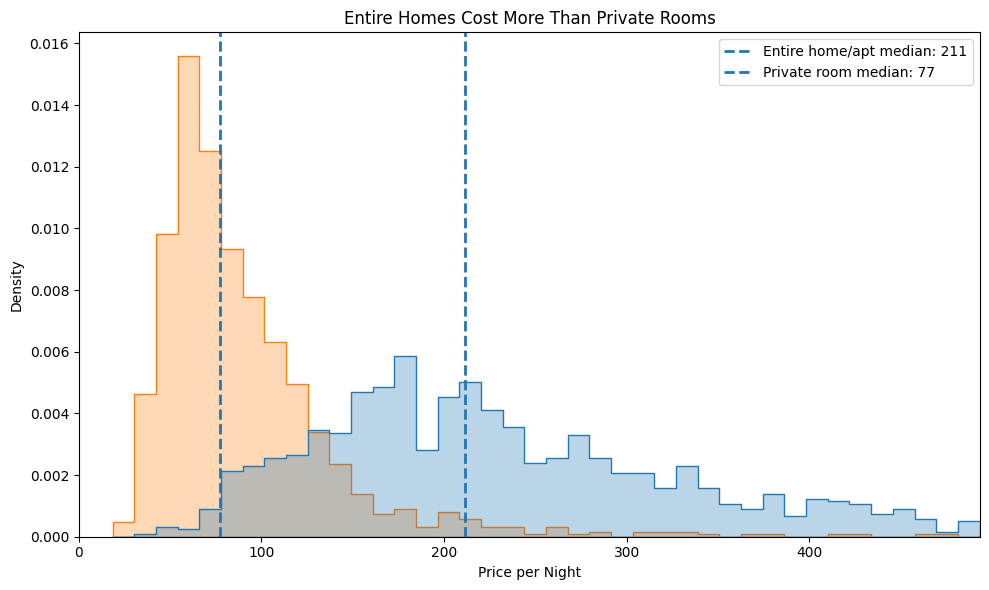

In [10]:
# Task 1
# YOUR CODE HERE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean the price column and convert it to numbers
df['price'] = (
    df['price']
    .astype(str)
    .str.replace(r'[^0-9.]', '', regex=True)
)

df['price'] = pd.to_numeric(df['price'], errors='coerce')

# 2. Remove missing and invalid prices
df = df[df['price'].notna() & (df['price'] > 0)].copy()

# 3. Calculate the 95th percentile and cap extreme prices
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()

print(f"95th percentile price: {p95:.2f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))

# 4. Select the two room types
room_types = ['Entire home/apt', 'Private room']
plot_df = df_cap[df_cap['room_type'].isin(room_types)]

# 5. Draw overlapping histograms
plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df,
    x='price',
    hue='room_type',
    bins=40,
    element='step',
    stat='density',
    common_norm=False,
    alpha=0.3
)

# 6. Add a median line for each room type
for room in room_types:
    median_price = plot_df.loc[
        plot_df['room_type'] == room, 'price'
    ].median()

    plt.axvline(
        median_price,
        linestyle='--',
        linewidth=2,
        label=f'{room} median: {median_price:.0f}'
    )

plt.title('Entire Homes Cost More Than Private Rooms')
plt.xlabel('Price per Night')
plt.ylabel('Density')
plt.xlim(0, p95)
plt.legend()
plt.tight_layout()
plt.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Boroughs ranked by median reviews per month:
neighbourhood_cleansed
City of London            1.85
Croydon                   0.80
Hammersmith and Fulham    0.69
Richmond upon Thames      0.69
Westminster               0.68
Kingston upon Thames      0.66
Islington                 0.64
Tower Hamlets             0.62
Southwark                 0.62
Ealing                    0.61
Camden                    0.60
Lambeth                   0.59
Hounslow                  0.53
Barking and Dagenham      0.52
Redbridge                 0.51
Kensington and Chelsea    0.50
Hackney                   0.48
Greenwich                 0.48
Wandsworth                0.48
Brent                     0.47
Haringey                  0.44
Merton                    0.43
Waltham Forest            0.41
Sutton                    0.38
Lewisham                  0.34
Barnet                    0.34
Newham                    0.34
Enfield                   0.33
Bromley                   0.31
Harrow                    0.28
Be

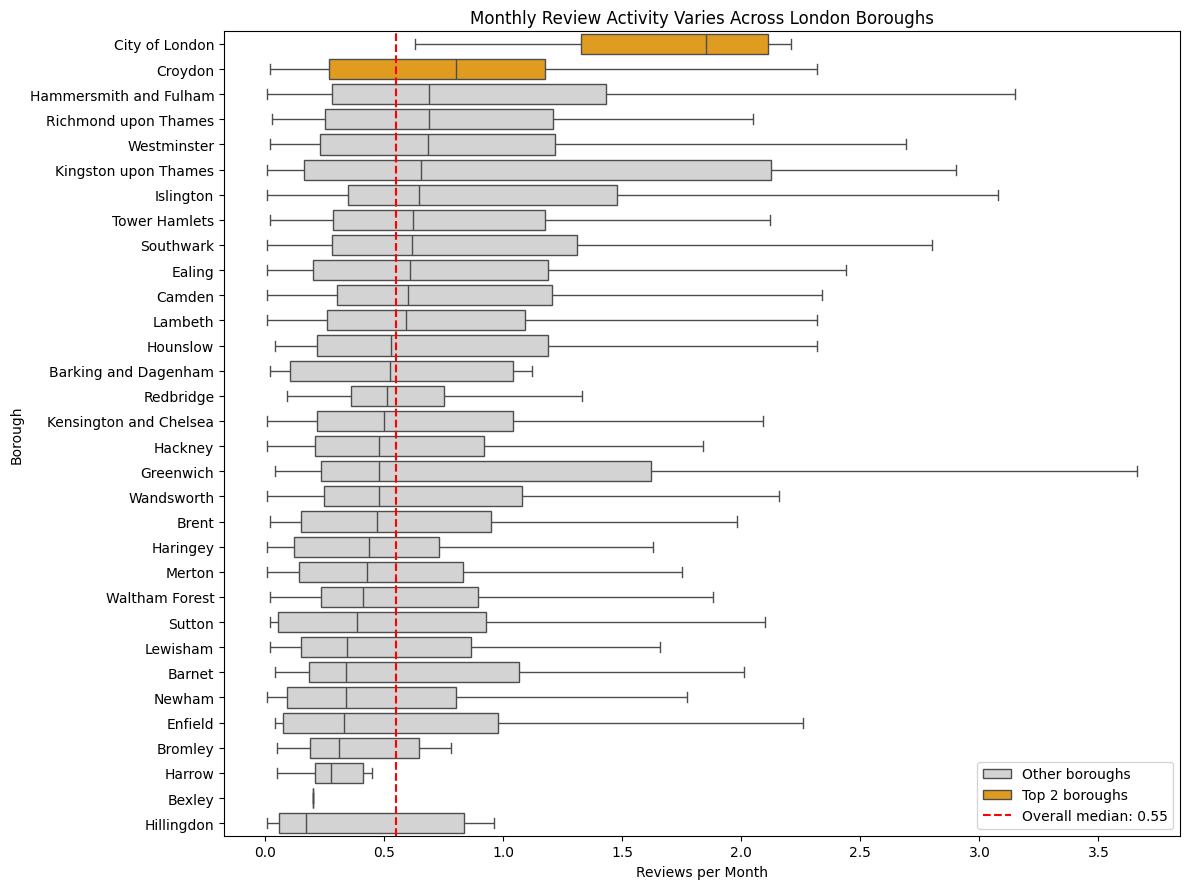

In [11]:
# Task 2
# YOUR CODE HERE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert reviews per month to numeric
df['reviews_per_month'] = pd.to_numeric(
    df['reviews_per_month'], errors='coerce'
)

# 2. Remove missing and zero-review listings
reviews_df = df[
    df['reviews_per_month'].notna()
    & (df['reviews_per_month'] > 0)
].copy()

# 3. Identify the borough column
borough_col = 'neighbourhood_cleansed'

# 4. Calculate median monthly reviews for each borough
borough_medians = (
    reviews_df.groupby(borough_col)['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

print("Boroughs ranked by median reviews per month:")
print(borough_medians.round(2))

# 5. Highlight the top two boroughs
top_two = borough_medians.head(2).index.tolist()

reviews_df['borough_group'] = reviews_df[borough_col].apply(
    lambda x: 'Top 2 boroughs' if x in top_two else 'Other boroughs'
)

# 6. Plot horizontal box plots, ordered by median
plt.figure(figsize=(12, 9))

sns.boxplot(
    data=reviews_df,
    x='reviews_per_month',
    y=borough_col,
    order=borough_medians.index,
    hue='borough_group',
    palette={
        'Top 2 boroughs': 'orange',
        'Other boroughs': 'lightgray'
    },
    dodge=False,
    showfliers=False
)

# 7. Add the overall median
overall_median = reviews_df['reviews_per_month'].median()
plt.axvline(
    overall_median,
    color='red',
    linestyle='--',
    label=f'Overall median: {overall_median:.2f}'
)

plt.title('Monthly Review Activity Varies Across London Boroughs')
plt.xlabel('Reviews per Month')
plt.ylabel('Borough')
plt.legend()
plt.tight_layout()
plt.show()